In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
from tsp_deterministic_annealing import deterministic_annealing
import tsplib95
import random
from tsp_hillclimbing import calculate_distances, evaluate_function

In [4]:
data_filepath = r"D:\PycharmProjects\University\HeuristicAlgorithms\data\berlin52.tsp"
data_opt_filepath = r"D:\PycharmProjects\University\HeuristicAlgorithms\data\berlin52.opt.tour"

problem = tsplib95.load(data_filepath)
opt = tsplib95.load(data_opt_filepath)

cities = list(problem.node_coords.values())
N = problem.dimension

distances = calculate_distances(cities, N)
initial_route = list(range(N))
random.shuffle(initial_route)

In [41]:
best_route, best_score, history = deterministic_annealing(distances, initial_route, t_init=2000.0, alpha=0.9995, max_iter=50000)

In [42]:
opt_route = [node - 1 for node in opt.tours[0]]
opt_score = evaluate_function(opt_route, distances)
difference = best_score - opt_score
difference_percentage = (difference / opt_score) * 100

print(f"Оптимальний маршрут: {opt_score:.2f}")
print(f"Найкращий маршрут алгоритму: {best_score:.2f}")
print(f"Різниця між найкращим і оптимальним: {difference:.2f} ({difference_percentage:.2f}%)")

Оптимальний маршрут: 7544.37
Найкращий маршрут алгоритму: 7780.38
Різниця між найкращим і оптимальним: 236.01 (3.13%)


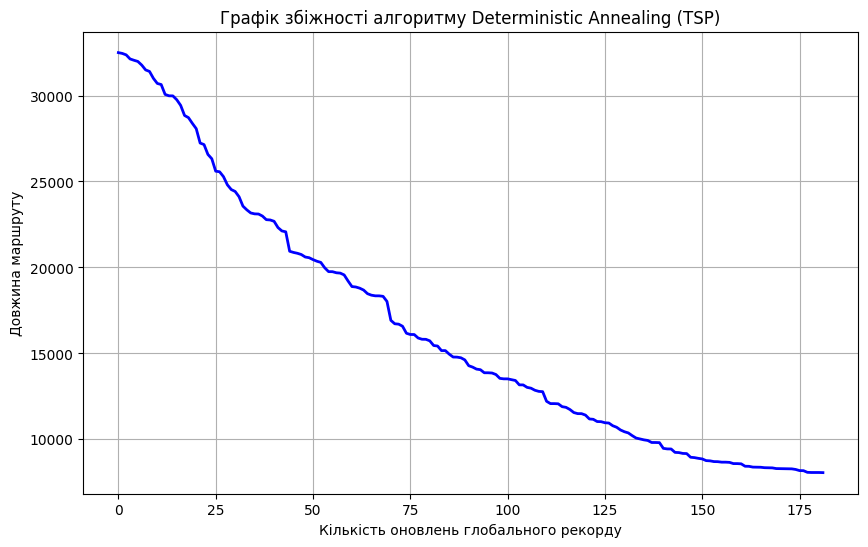

In [30]:
plt.figure(figsize=(10, 6))
plt.plot(history, color='blue', linewidth=2)
plt.title('Графік збіжності алгоритму Deterministic Annealing (TSP)')
plt.xlabel('Кількість оновлень глобального рекорду')
plt.ylabel('Довжина маршруту')
plt.grid(True)
plt.show()